Loaded 20640 rows, 10 columns
Missing values: {'total_bedrooms': 207}

             Model  MAE ($)  RMSE ($)    R2
Linear Regression    49645     69127 0.635
    Random Forest    31767     49500 0.813


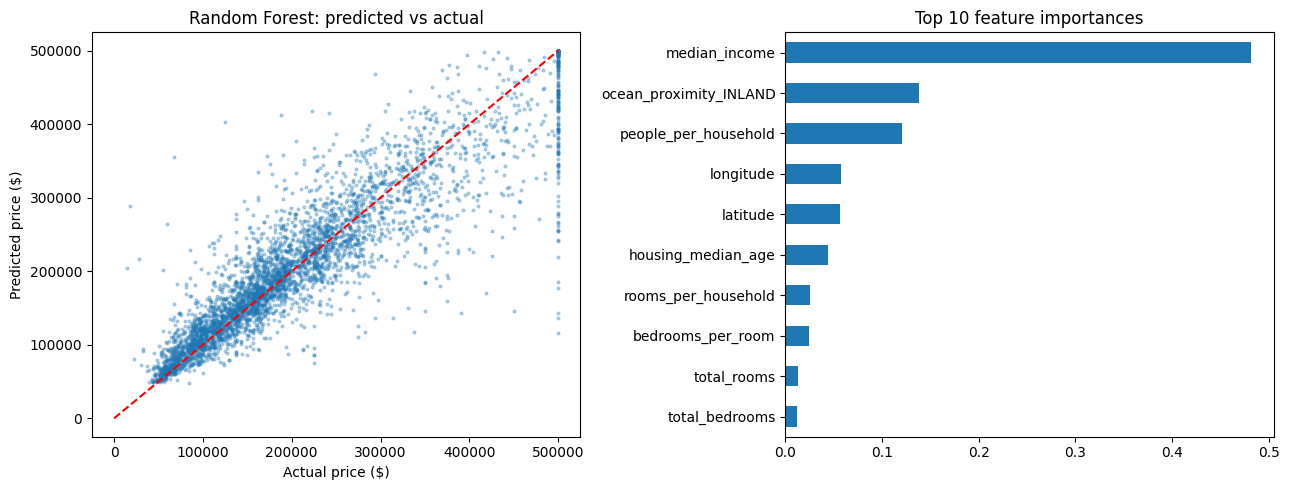

In [ ]:
# California House Price Predictor - single-file version for Google Colab
# Paste into one Colab cell and run. No extra installs needed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load data -------------------------------------------------------------
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(URL)
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns")
print("Missing values:", df.isna().sum()[df.isna().sum() > 0].to_dict())

# 2. Feature engineering ---------------------------------------------------
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["people_per_household"] = df["population"] / df["households"]

X = df.drop(columns="median_house_value")
y = df["median_house_value"]
cat_cols = ["ocean_proximity"]
num_cols = [c for c in X.columns if c not in cat_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Preprocessing + models ------------------------------------------------
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
}

# 4. Train & evaluate ------------------------------------------------------
results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"Model": name,
                    "MAE ($)": round(mean_absolute_error(y_test, pred)),
                    "RMSE ($)": round(root_mean_squared_error(y_test, pred)),
                    "R2": round(r2_score(y_test, pred), 3)})
    fitted[name] = (pipe, pred)
print("\n", pd.DataFrame(results).to_string(index=False))

best_pipe, best_pred = fitted["Random Forest"]

# 5. Plots -----------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, best_pred, s=4, alpha=0.3)
ax[0].plot([0, y.max()], [0, y.max()], "r--")
ax[0].set(xlabel="Actual price ($)", ylabel="Predicted price ($)",
          title="Random Forest: predicted vs actual")
names = [n.split("__")[1] for n in best_pipe.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(best_pipe.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)
imp.plot.barh(ax=ax[1], title="Top 10 feature importances")
plt.tight_layout()
plt.show()

# 6. Interactive demo (sliders) --------------------------------------------
import ipywidgets as w
from IPython.display import display

income = w.FloatSlider(value=4.0, min=0.5, max=15, step=0.1, description="Income (x$10k)")
age = w.IntSlider(value=25, min=1, max=52, description="House age")
rooms = w.FloatSlider(value=5.0, min=1, max=10, step=0.1, description="Rooms/household")
people = w.FloatSlider(value=3.0, min=1, max=8, step=0.1, description="People/household")
lat = w.FloatSlider(value=34.0, min=32.5, max=42, step=0.1, description="Latitude")
lon = w.FloatSlider(value=-118.3, min=-124.3, max=-114.3, step=0.1, description="Longitude")
ocean = w.Dropdown(options=["<1H OCEAN", "INLAND", "NEAR OCEAN", "NEAR BAY", "ISLAND"],
                   description="Ocean")
out = w.Output()

def predict(_=None):
    hh, ratio = 500, 0.2
    row = pd.DataFrame([{
        "longitude": lon.value, "latitude": lat.value, "housing_median_age": age.value,
        "total_rooms": rooms.value * hh, "total_bedrooms": rooms.value * hh * ratio,
        "population": people.value * hh, "households": hh,
        "median_income": income.value, "ocean_proximity": ocean.value,
        "rooms_per_household": rooms.value, "bedrooms_per_room": ratio,
        "people_per_household": people.value}])
    with out:
        out.clear_output()
        print(f"Estimated median house value: ${best_pipe.predict(row)[0]:,.0f}")

for s in (income, age, rooms, people, lat, lon, ocean):
    s.observe(predict, names="value")
display(w.VBox([income, age, rooms, people, lat, lon, ocean, out]))
predict()